# 05 — Build the final dataset (one row per firm) and a first look

**Goal:** merge the 10-K info, text scores, and event returns into `outputs/final_dataset.csv`. This is the file the dashboard and the proposal read from.

**Industry:** we use the **Fama-French 12 industries**, built from the firm's SEC SIC code. GICS is proprietary (S&P/MSCI) and Yahoo's sector labels are *current*, not as of 2025. The SIC→FF12 ranges are transcribed from Ken French's `Siccodes12.txt` (Data Library → "Detail for 12 Industry Portfolios").

**Market cap** = shares outstanding from the pre-event 10-K × raw closing price on Apr 2, 2025 (day −1). Both are known before the announcement.

| | |
|---|---|
| **Inputs** | `tenk_manifest.csv`, `filing_scores.csv`, `event_car.csv`, `daily_prices.csv`, `download_problems.csv` |
| **Outputs** | `outputs/final_dataset.csv`, `outputs/summary_stats.csv`, `outputs/sample_log.csv`, `outputs/scatter_tariff_vs_car.png` |


In [1]:
# --- Setup: find the repo root and load shared settings from code/config.py ---
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "run_all.py").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Can't find the repo root. Run this from inside the project folder.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "code"))

import config as cfg
print("Repo root:", ROOT)

Repo root: /content/project


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Fama-French 12 industries from SIC (source: Ken French Data Library, Siccodes12.txt)
FF12_RANGES = {
    "NoDur": [(100, 999), (2000, 2399), (2700, 2749), (2770, 2799), (3100, 3199), (3940, 3989)],
    "Durbl": [(2500, 2519), (2590, 2599), (3630, 3659), (3710, 3711), (3714, 3714), (3716, 3716),
              (3750, 3751), (3792, 3792), (3900, 3939), (3990, 3999)],
    "Manuf": [(2520, 2589), (2600, 2699), (2750, 2769), (3000, 3099), (3200, 3569), (3580, 3629),
              (3700, 3709), (3712, 3713), (3715, 3715), (3717, 3749), (3752, 3791), (3793, 3799),
              (3830, 3839), (3860, 3899)],
    "Enrgy": [(1200, 1399), (2900, 2999)],
    "Chems": [(2800, 2829), (2840, 2899)],
    "BusEq": [(3570, 3579), (3660, 3692), (3694, 3699), (3810, 3829), (7370, 7379)],
    "Telcm": [(4800, 4899)],
    "Utils": [(4900, 4949)],
    "Shops": [(5000, 5999), (7200, 7299), (7600, 7699)],
    "Hlth":  [(2830, 2839), (3693, 3693), (3840, 3859), (8000, 8099)],
    "Money": [(6000, 6999)],
}

def ff12(sic):
    if pd.isna(sic):
        return None
    sic = int(sic)
    for name, ranges in FF12_RANGES.items():
        if any(lo <= sic <= hi for lo, hi in ranges):
            return name
    return "Other"

assert ff12(3571) == "BusEq" and ff12(5331) == "Shops" and ff12(2834) == "Hlth" and ff12(9999) == "Other"

## Merge

In [3]:
manifest = pd.read_csv(cfg.MANIFEST_CSV, dtype={"cik": str})
scores = pd.read_csv(cfg.SCORES_CSV)
car = pd.read_csv(cfg.CAR_CSV)
prices = pd.read_csv(cfg.PRICES_CSV, parse_dates=["date"])

# Raw close on the last trading day BEFORE day 0 (Apr 2, 2025)
pre = prices[prices["date"] < pd.Timestamp(cfg.EVENT_DAY0)]
close_pre = pre.sort_values("date").groupby("ticker").tail(1)[["ticker", "date", "close"]]
close_pre.columns = ["ticker", "price_date", "close_pre_event"]

df = (manifest[["ticker", "company", "cik", "sic", "sic_description", "filing_date",
                "shares_outstanding", "shares_source"]]
      .merge(scores.drop(columns="filing_date"), on="ticker", how="inner", validate="1:1")
      .merge(car, on="ticker", how="inner", validate="1:1")
      .merge(close_pre, on="ticker", how="left", validate="1:1"))

df["ff12_industry"] = df["sic"].apply(ff12)
df["market_cap_musd"] = df["shares_outstanding"] * df["close_pre_event"] / 1e6

cols = ["ticker", "company", "ff12_industry", "sic", "filing_date", "market_cap_musd",
        "word_count", "tariff_score", "import_score", "china_score",
        "car_0_1", "car_m1_1", "car_0_3", "mktadj_0_1", "beta", "pre_event_vol",
        "tariff_hits", "import_hits", "china_hits", "shares_source"]
detail_cols = [c for c in df.columns if c.startswith("n_")]
final = df[cols + detail_cols].sort_values("tariff_score", ascending=False).reset_index(drop=True)
final.to_csv(cfg.FINAL_CSV, index=False)
final[cols].round(4)

,ticker,company,ff12_industry,sic,filing_date,market_cap_musd,word_count,tariff_score,import_score,china_score,car_0_1,car_m1_1,car_0_3,mktadj_0_1,beta,pre_event_vol,tariff_hits,import_hits,china_hits,shares_source
0,NKE,"NIKE, Inc.",Manuf,3021,2024-07-25,9.858329e+04,52971,5.6635,9.8167,5.4747,-0.0530,-0.0521,-0.1118,-0.0065,0.5472,0.0210,30,52,29,weighted_avg_basic
1,BBY,BEST BUY CO INC,Shops,5731,2025-03-19,1.600702e+04,40047,4.2450,1.4982,2.2474,-0.1300,-0.1161,-0.1869,-0.0992,0.7116,0.0255,17,6,9,cover_page
2,TGT,TARGET CORP,Shops,5331,2025-03-12,4.818632e+04,31344,2.5523,2.2333,0.6381,-0.0245,-0.0137,-0.0839,0.0145,0.6061,0.0178,8,7,2,cover_page
3,COST,COSTCO WHOLESALE CORP /NEW,Shops,5331,2024-10-09,4.276014e+05,29729,2.3546,1.6819,2.3546,0.0294,0.0353,0.0329,0.0576,0.7502,0.0164,7,5,7,cover_page
4,JNJ,JOHNSON & JOHNSON,Hlth,2834,2025-02-13,3.740473e+05,57826,1.5564,1.2105,1.5564,-0.0288,-0.0146,-0.0534,0.0954,-0.1442,0.0153,9,7,9,cover_page
5,TSLA,"Tesla, Inc.",Durbl,3711,2025-01-30,9.095024e+05,54723,1.2792,0.7310,3.8375,0.1335,0.1686,0.1046,-0.0511,2.7293,0.0442,7,4,21,cover_page
6,XOM,EXXON MOBIL CORP,Enrgy,2911,2025-02-19,5.149261e+05,57187,1.0492,1.9235,1.2241,-0.1013,-0.1060,-0.1324,-0.0167,0.2191,0.0140,6,11,7,cover_page
7,CAT,CATERPILLAR INC,Manuf,3531,2025-02-14,1.599447e+05,58149,0.8599,0.8599,2.5796,-0.0195,-0.0139,-0.0482,-0.0364,1.1473,0.0173,5,5,15,cover_page
8,AAPL,Apple Inc.,BusEq,3571,2024-11-01,3.384282e+06,28293,0.7069,3.1810,6.7154,-0.0621,-0.0656,-0.1328,-0.0575,0.9666,0.0180,2,9,19,cover_page
9,MSFT,MICROSOFT CORP,BusEq,7372,2024-07-30,2.840461e+06,49301,0.6085,0.8113,1.0142,0.0625,0.0561,0.0687,0.0486,1.1157,0.0163,3,4,5,cover_page


## Sample log: what happened to every requested ticker

In [4]:
probs = pd.read_csv(cfg.DOWNLOAD_PROBLEMS_CSV)
log = pd.DataFrame({"ticker": cfg.TICKERS})
log["in_final"] = log["ticker"].isin(final["ticker"])
log = log.merge(probs.groupby("ticker")["problem"].apply("; ".join).reset_index(), on="ticker", how="left")
log.to_csv(cfg.OUTPUT_DIR / "sample_log.csv", index=False)
print(f"Requested {len(log)} tickers; {log['in_final'].sum()} in final dataset.")
log

Requested 10 tickers; 10 in final dataset.


,ticker,in_final,problem
0,AAPL,True,NaN
1,NKE,True,NaN
2,BBY,True,NaN
3,TGT,True,NaN
4,COST,True,NaN
5,CAT,True,NaN
6,TSLA,True,NaN
7,MSFT,True,NaN
8,JNJ,True,NaN
9,XOM,True,NaN


## Checks

In [5]:
assert final["ticker"].is_unique, "duplicate firms"
assert (final["filing_date"] < cfg.TENK_CUTOFF).all(), "LOOK-AHEAD in 10-K dates"
missing = final[cols].isna().sum()
print("Missing values per column:\n", missing[missing > 0] if missing.any() else "none")

summary = final[["market_cap_musd", "word_count", "tariff_score", "import_score", "china_score",
                 "car_0_1", "car_0_3", "beta", "pre_event_vol"]].describe().T
summary.to_csv(cfg.OUTPUT_DIR / "summary_stats.csv")
summary.round(4)

Missing values per column:
 none


,count,mean,std,min,25%,50%,75%,max
market_cap_musd,10.0,877354.1637,1.214590e+06,16007.0248,113923.6542,400824.3738,810858.3238,3.384282e+06
word_count,10.0,45957.0000,1.236790e+04,28293.0000,33519.7500,51136.0000,56571.0000,5.814900e+04
tariff_score,10.0,2.0875,1.678100e+00,0.6085,0.9072,1.4178,2.5029,5.663500e+00
import_score,10.0,2.3947,2.714100e+00,0.7310,0.9475,1.5900,2.1558,9.816700e+00
china_score,10.0,2.7642,1.999800e+00,0.6381,1.3071,2.3010,3.5230,6.715400e+00
car_0_1,10.0,-0.0194,7.780000e-02,-0.1300,-0.0598,-0.0267,0.0172,1.335000e-01
car_0_3,10.0,-0.0543,9.550000e-02,-0.1869,-0.1272,-0.0687,0.0126,1.046000e-01
beta,10.0,0.8649,7.651000e-01,-0.1442,0.5619,0.7309,1.0784,2.729300e+00
pre_event_vol,10.0,0.0206,8.900000e-03,0.0140,0.0163,0.0175,0.0203,4.420000e-02


## Check by hand: rebuild one row from the raw files
For one firm, recompute market cap and tariff score straight from the input files (not from the merged table) and confirm they match.

In [6]:
t = final["ticker"].iloc[0]
m_row = manifest.set_index("ticker").loc[t]
close_apr2 = prices[(prices["ticker"] == t) & (prices["date"] == pd.Timestamp("2025-04-02"))]["close"].iloc[0]
hand_mcap = m_row["shares_outstanding"] * close_apr2 / 1e6

s_row = scores.set_index("ticker").loc[t]
hand_score = (s_row["n_tariff"] + s_row["n_trade_policy"] + s_row["n_duties"] + s_row["n_section_301_232"]) \
             / s_row["word_count"] * 10_000

f_row = final.set_index("ticker").loc[t]
print(f"{t}: market cap  hand = {hand_mcap:,.1f}  pipeline = {f_row['market_cap_musd']:,.1f}  ($ millions)")
print(f"{t}: tariff score hand = {hand_score:.4f}  pipeline = {f_row['tariff_score']:.4f}")
assert abs(hand_mcap - f_row["market_cap_musd"]) < 1e-6 * hand_mcap
assert abs(hand_score - f_row["tariff_score"]) < 1e-9
print("Hand check passed.")

NKE: market cap  hand = 98,583.3  pipeline = 98,583.3  ($ millions)
NKE: tariff score hand = 5.6635  pipeline = 5.6635
Hand check passed.


## First look: tariff exposure vs. announcement-window CAR
⚠️ **v0 sample only (about 10 firms).** No statistical conclusions. This chart only shows the pipeline runs end to end. The real test (Checkpoint 3) is a cross-sectional regression on the full S&P 500 sample with industry fixed effects:

$$CAR_i[0,+1] = a + b\cdot \text{TariffScore}_i + c'\text{Controls}_i + \text{Industry FE} + e_i$$

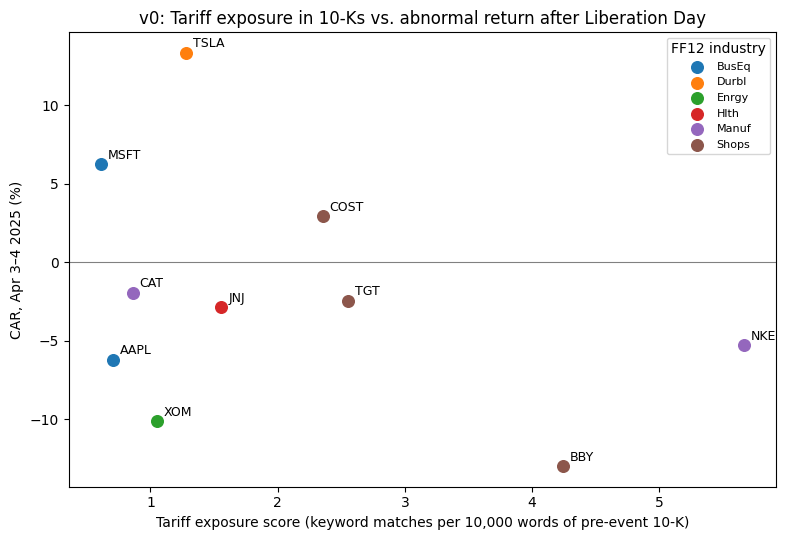

n = 10; correlation(tariff_score, car_0_1) = -0.38  (v0 only, not a result)


In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for ind, g in final.groupby("ff12_industry"):
    ax.scatter(g["tariff_score"], g["car_0_1"] * 100, s=70, label=ind)
for _, r in final.iterrows():
    ax.annotate(r["ticker"], (r["tariff_score"], r["car_0_1"] * 100),
                xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Tariff exposure score (keyword matches per 10,000 words of pre-event 10-K)")
ax.set_ylabel("CAR, Apr 3–4 2025 (%)")
ax.set_title("v0: Tariff exposure in 10-Ks vs. abnormal return after Liberation Day")
ax.legend(title="FF12 industry", fontsize=8)
fig.tight_layout()
fig.savefig(cfg.OUTPUT_DIR / "scatter_tariff_vs_car.png", dpi=150)
plt.show()

print(f"n = {len(final)}; correlation(tariff_score, car_0_1) = {final['tariff_score'].corr(final['car_0_1']):.2f}  (v0 only, not a result)")